# Defect Type with YOLO (Real-IAD)

## 1. Settings

In [4]:
import json, os, shutil
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

category = "audiojack"   # change this for each product

base = os.path.join("Real-IAD", "realiad_512")   # the Real-IAD folder is next to this notebook
img_dir = os.path.join(base, category)
json_path = os.path.join(base, "JSON", "realiad_jsons", category + ".json")
out = os.path.abspath(os.path.join("yolo_data", category))   # the prepared YOLO folder, next to this notebook
runs_dir = os.path.abspath("yolo_runs")   # the training results, next to this notebook
print("notebook folder:", os.getcwd())
product_dir = os.path.join("result", "category", category)   # result/category/audiojack: what you copy to Streamlit

# code -> full name of the defect
defect_names = {"AK": "pit", "BX": "deformation", "CH": "abrasion", "HS": "scratch",
                "PS": "damage", "QS": "missing parts", "YW": "foreign objects", "ZW": "contamination"}

notebook folder: /home/ali/NEW test


## 2. Prepare the data for YOLO
Only the defective images.

In [5]:
f = open(json_path)
data = json.load(f)
f.close()

# the defect types of this product
classes = []
names = []
for item in data["test"]:
    code = item["anomaly_class"]
    if code != "OK" and code not in classes:
        classes.append(code)
        names.append(defect_names[code])

# start from empty folders
if os.path.exists(out):
    shutil.rmtree(out)
for split in ["train", "val", "test"]:
    os.makedirs(os.path.join(out, "images", split))
    os.makedirs(os.path.join(out, "labels", split))

for item in data["test"]:
    if item["anomaly_class"] != "OK":
        sample = item["image_path"].split("/")[-2]
        digit = int(sample[-1])
        if digit <= 6:
            split = "train"
        elif digit == 7:
            split = "val"
        else:
            split = "test"

        name = os.path.basename(item["image_path"])
        shutil.copy(os.path.join(img_dir, item["image_path"]), os.path.join(out, "images", split, name))

        # box = smallest rectangle around the white area of the mask
        mask = np.array(Image.open(os.path.join(img_dir, item["mask_path"])).convert("L")) > 127
        ys, xs = np.where(mask)
        h, w = mask.shape
        x_center = (xs.min() + xs.max() + 1) / 2 / w
        y_center = (ys.min() + ys.max() + 1) / 2 / h
        box_w = (xs.max() - xs.min() + 1) / w
        box_h = (ys.max() - ys.min() + 1) / h

        # YOLO label: class number, x center, y center, width, height
        f = open(os.path.join(out, "labels", split, name.replace(".jpg", ".txt")), "w")
        f.write(str(classes.index(item["anomaly_class"])) + " " + str(x_center) + " " + str(y_center) + " " + str(box_w) + " " + str(box_h))
        f.close()

# data.yaml: where the data is and the full names of the classes
f = open(os.path.join(out, "data.yaml"), "w")
f.write("path: " + out + "\n")
f.write("train: images/train\n")
f.write("val: images/val\n")
f.write("test: images/test\n")
f.write("names: " + str(names) + "\n")
f.close()

print(names)
for split in ["train", "val", "test"]:
    print(split, len(os.listdir(os.path.join(out, "images", split))), "images")

['scratch', 'missing parts', 'contamination', 'deformation']
train 912 images
val 136 images
test 248 images


## 3. Load a ready YOLO model

In [3]:
from ultralytics import YOLO

model = YOLO("yolo26s.pt")

## 4. Tune it on our images

In [4]:
# project / name: the folder of the result, exist_ok: use the same folder when you run it again
model.train(data=os.path.join(out, "data.yaml"), epochs=50,
            project=runs_dir, name=category, exist_ok=True)

Ultralytics 8.4.215 🚀 Python-3.12.3 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 4060, 8188MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/ali/NEW test/yolo_data/audiojack/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=audiojack, nbs=64, nms=None,

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x73956371a660>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0

## 5. Test it
The test images were never used in training. The table shows the result for each defect type.

In [5]:
finetuned_model = YOLO(os.path.join(runs_dir, category, "weights", "best.pt"))

metrics = finetuned_model.val(data=os.path.join(out, "data.yaml"), split="test")

Ultralytics 8.4.215 🚀 Python-3.12.3 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 4060, 8188MiB)
YOLO26s summary (fused): 120 layers, 9,466,728 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 130.0±66.4 MB/s, size: 60.2 KB)
val: Scanning /home/ali/NEW test/yolo_data/audiojack/labels/test... 248 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 248/248 1.0Kit/s 0.2s<0.1s
val: New cache created: /home/ali/NEW test/yolo_data/audiojack/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 6.1it/s 2.6s0.1s
                   all        248        248      0.941      0.855      0.911      0.656
               scratch         28         28      0.918      0.821       0.91      0.639
         missing parts         58         58      0.941      0.832      0.912      0.587
         contamination         43         43      0.925      0.791       0.83      0.622
           deforma


image 1/1 /home/ali/NEW test/yolo_data/audiojack/images/test/audiojack__0098_NG_BX_C5_20231023113551.jpg: 640x640 1 deformation, 6.1ms
Speed: 1.8ms preprocess, 6.1ms inference, 2.1ms postprocess per image at shape (1, 3, 640, 640)


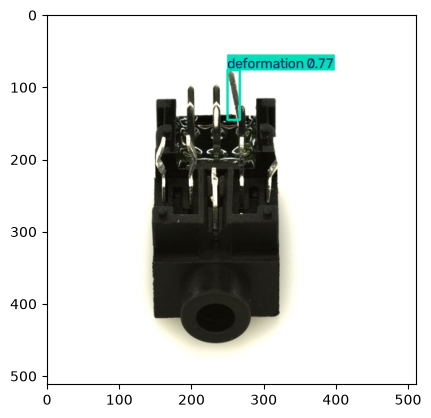

In [6]:
# one test image
folder = os.path.join(out, "images", "test")
results = finetuned_model(os.path.join(folder, os.listdir(folder)[0]))

plt.imshow(results[0].plot()[..., ::-1]);

## 6. Make the test images for Streamlit
They go to `result/category/audiojack/image/C1` ... `C5` next to this notebook, with the original image names. Only the test samples (last digit 8 or 9, the same test split as above), never the train (0-6) or validation (7) samples.

In [16]:
views = ["C1", "C2", "C3", "C4", "C5"]
test_out = os.path.join(product_dir, "image")

if os.path.exists(test_out):
    shutil.rmtree(test_out)

for v in views:
    os.makedirs(os.path.join(test_out, v))

done = set()

for item in data["test"]:
    parts = item["image_path"].replace("\\", "/").split("/")

    if category in parts:
        parts = parts[parts.index(category) + 1:]

    sample = parts[-2]

    if int(sample[1:]) % 10 not in (8, 9):
        continue

    code = item["anomaly_class"]
    problem = "normal" if code == "OK" else defect_names[code]
    sample_id = problem.replace(" ", "_") + "_" + sample

    if sample_id in done:
        continue
    done.add(sample_id)

    folder = os.path.join(img_dir, *parts[:-1])

    for name in os.listdir(folder):
        if not name.lower().endswith(".jpg"):
            continue

        for view in views:
            if f"_{view}_" in name:
                shutil.copy2(
                    os.path.join(folder, name),
                    os.path.join(test_out, view, sample_id + "__" + name)
                )
                break

### Check
No image of a train or validation sample must be inside.

In [14]:
# names of the images of the train (0-6) and validation (7) samples
train_names = []
for item in data["test"]:
    if int(item["image_path"].split("/")[-2][-1]) < 8:
        train_names.append(os.path.basename(item["image_path"]))

total = 0
wrong = 0
for view in views:
    folder = os.path.join(test_out, view)
    print(view, len(os.listdir(folder)), "images")
    for name in os.listdir(folder):
        total = total + os.path.getsize(os.path.join(folder, name))
        if name in train_names:
            wrong = wrong + 1

print("images from train or validation samples:", wrong)
print("size:", round(total / 1000000), "MB")
print("folder:", test_out)

C1 157 images
C2 157 images
C3 157 images
C4 157 images
C5 157 images
images from train or validation samples: 0
size: 48 MB
folder: result/category/audiojack/image


## 7. Save the YOLO model for Streamlit
It goes in the same `models` folder as the PatchCore files. After this, copy the whole `result` folder next to `app.py`.

In [9]:
best_path = os.path.join(runs_dir, category, "weights", "best.pt")

os.makedirs(os.path.join(product_dir, "models"), exist_ok=True)
shutil.copy(best_path, os.path.join(product_dir, "models", "yolo_type.pt"))

# check the files and their size
for name in os.listdir(os.path.join(product_dir, "models")):
    print(name, round(os.path.getsize(os.path.join(product_dir, "models", name)) / 1000000), "MB")

patchcore_C3.ckpt 255 MB
patchcore_C2.ckpt 255 MB
thresholds.json 0 MB
patchcore_C5.ckpt 255 MB
yolo_type.pt 20 MB
patchcore_C1.ckpt 255 MB
patchcore_C4.ckpt 255 MB
